## Anomaly Detection: Historical Reporting Patterns



**Research objective.** Design, evaluate and package an *exploratory anomaly-screening method* that identifies area/category combinations whose incoming complaint volume is unusually high relative to comparable historical days.



**Safety and interpretation.** An anomaly candidate means *unusually elevated reporting*; it is not proof of a defect, a statistical-significance result, or an automatic repair priority. 

## Problem definition and study design

**Research questions**

1. What constitutes the *normal* daily complaint count for a borough–ZIP area and a complaint category?
2. How much variation is explained by weekday and season?
3. How should sparse history and unsupported geographic areas be handled?
4. How should an elevated count be separated from a strong cross-window candidate?
5. How stable are candidates when report floors or strength requirements change?


**Baseline period:** Jan 1, 2023–Dec 31, 2025. **Example reporting day:** Nov 9, 2026 (only for historical notebook experiments).

## Input data and reproducibility setup



The complaint taxonomy is an upstream project policy input, not a learned anomaly model. Project-root discovery is portable across checkouts.

In [24]:
from pathlib import Path
from collections import Counter
from datetime import date, datetime
from time import perf_counter
import hashlib
import json
import math
import re

import numpy as np
import pandas as pd

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "config" / "config.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from inside the project folder.")
MASTER = ROOT / "data/processed/nyc311_infrastructure_cleaned.csv"
TAXONOMY = ROOT / "outputs/tables/dbscan/dbscan_action_taxonomy_v1.csv"
TEST_BATCH = ROOT / "outputs/tests/phase_17_4c_backend_verified/verified_500_backend_results.csv"
REPORTING_DAY = "2026-11-09"  # documented synthetic example; replace for new batches
START_DAY, END_DAY = "2023-01-01", "2025-12-31"
VALID_BOROUGHS = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}

for path in (MASTER, TAXONOMY):
    if not path.is_file():
        raise FileNotFoundError(f"Required upstream input unavailable: {path}")

source_cols = {"created_date", "complaint_type", "borough", "incident_zip"}
found_cols = set(pd.read_csv(MASTER, nrows=0).columns)
assert source_cols.issubset(found_cols), f"Master dataset is missing {source_cols - found_cols}"
taxonomy = pd.read_csv(TAXONOMY, dtype="string")
assert "complaint_category" in taxonomy.columns
supported_categories = sorted({str(s).strip().upper()
                               for s in taxonomy["complaint_category"].dropna()
                               if str(s).strip()})
assert supported_categories
historical_calendar = pd.date_range(START_DAY, END_DAY, freq="D")
assert len(historical_calendar) == 1096

print("Project:", ROOT)
print("Historical master:", MASTER.relative_to(ROOT))
print("Taxonomy:", TAXONOMY.relative_to(ROOT))
print("Supported categories:", len(supported_categories))
print("Baseline calendar days:", len(historical_calendar))
print("No prior anomaly engine or baseline loaded.")

Project: D:\Urban-Infrastructure-Pulse-Intelligence
Historical master: data\processed\nyc311_infrastructure_cleaned.csv
Taxonomy: outputs\tables\dbscan\dbscan_action_taxonomy_v1.csv
Supported categories: 15
Baseline calendar days: 1096
No prior anomaly engine or baseline loaded.


### 2.1 — Dataset provenance and quality checks

The historical builder will retain *audit counts* for rows excluded from the reference. Exclusions are not silently interpreted as zero reporting. Geographic eligibility here is based on borough/ZIP syntax; it is **not a point-in-polygon validation** of individual coordinates.

In [25]:
print("Master size (MiB):", round(MASTER.stat().st_size / 2**20, 1))
print("Historical period:", START_DAY, "through", END_DAY)
print("Valid boroughs:", ", ".join(sorted(VALID_BOROUGHS)))
print("Categories in taxonomy:", supported_categories)
print("Explicit limitation: raw complaint coordinates are not verified by this study.")

Master size (MiB): 447.8
Historical period: 2023-01-01 through 2025-12-31
Valid boroughs: BRONX, BROOKLYN, MANHATTAN, QUEENS, STATEN ISLAND
Categories in taxonomy: ['BRIDGE CONDITION', 'CURB CONDITION', 'ROOT/SEWER/SIDEWALK CONDITION', 'SEWER', 'SEWER MAINTENANCE', 'SIDEWALK CONDITION', 'STREET CONDITION', 'STREET LIGHT CONDITION', 'STREET SIGN - DAMAGED', 'STREET SIGN - DANGLING', 'STREET SIGN - MISSING', 'TRAFFIC SIGNAL CONDITION', 'WATER DRAINAGE', 'WATER LEAK', 'WATER MAINTENANCE']
Explicit limitation: raw complaint coordinates are not verified by this study.


## Historical data preparation: reconstruct the baseline

**Algorithm:** stream the cleaned master in chunks; interpret valid date prefixes as NYC-local dates; normalize area and category; group eligible records by `(area_id, complaint_category, historical_day)`; and count complaints.

The sparse table stores *nonzero observations*. When comparing a supported area/category against a historical calendar window, absent days count as zero in that window. However, areas without adequate active history must be labeled **insufficient evidence**, not anomalous.

In [26]:
def build_historical_baseline(master_path, supported, chunksize=60_000):
    counts = Counter()
    supported = set(supported)
    counters = Counter()
    for chunk in pd.read_csv(master_path, usecols=["created_date", "complaint_type", "borough", "incident_zip"],
                             dtype="string", keep_default_na=False, chunksize=chunksize):
        counters["source_rows"] += len(chunk)
        raw = chunk["created_date"].fillna("").astype("string").str.strip()
        # Offset-aware timestamps are excluded: do not silently infer their NYC-local day.
        has_offset = raw.str.contains(r"(?:[Zz]|[+-]\d{2}:?\d{2})$", regex=True, na=False)
        iso = raw.str.extract(r"^(\d{4}-\d{2}-\d{2})(?:$|[ T])", expand=False)
        us = raw.str.extract(r"^(\d{1,2}/\d{1,2}/\d{4})(?:$|[ T])", expand=False)
        day_iso = pd.to_datetime(iso, format="%Y-%m-%d", errors="coerce")
        day_us = pd.to_datetime(us, format="%m/%d/%Y", errors="coerce")
        days = day_iso.fillna(day_us).dt.strftime("%Y-%m-%d").fillna("")
        good_date = days.ne("") & ~has_offset
        period = good_date & days.ge(START_DAY) & days.le(END_DAY)
        cat = chunk["complaint_type"].fillna("").astype("string").str.strip().str.upper()
        borough = chunk["borough"].fillna("").astype("string").str.strip().str.upper()
        zipcode = chunk["incident_zip"].fillna("").astype("string").str.strip()
        good_area = borough.isin(VALID_BOROUGHS) & zipcode.str.fullmatch(r"\d{5}", na=False)
        good_cat = cat.isin(supported)
        eligible = period & good_area & good_cat
        counters["invalid_or_offset_date"] += int((~good_date).sum())
        counters["outside_period_valid_date"] += int((good_date & ~period).sum())
        counters["invalid_area_or_zip"] += int((~good_area).sum())
        counters["unsupported_category"] += int((~good_cat).sum())
        counters["eligible_rows"] += int(eligible.sum())
        if bool(eligible.any()):
            df = pd.DataFrame({
                "area_id": (borough + "_" + zipcode).loc[eligible].to_numpy(),
                "complaint_category": cat.loc[eligible].to_numpy(),
                "historical_day": days.loc[eligible].to_numpy(),
            })
            freq = df.groupby(["area_id", "complaint_category", "historical_day"], sort=False).size()
            counts.update({tuple(map(str, key)): int(value) for key, value in freq.items()})
    snapshot = pd.DataFrame(
        [(area, category, day, int(n)) for (area, category, day), n in counts.items()],
        columns=["area_id", "complaint_category", "historical_day", "complaint_count"]
    ).sort_values(["area_id", "complaint_category", "historical_day"]).reset_index(drop=True)
    areas = sorted({area for area, _, _ in counts})
    assert snapshot["complaint_count"].sum() == counters["eligible_rows"]
    assert not snapshot.duplicated(["area_id", "complaint_category", "historical_day"]).any()
    return counts, snapshot, areas, counters

print("Historical baseline construction function defined.")

Historical baseline construction function defined.


In [27]:
t0 = perf_counter()
historical_daily_counts, historical_snapshot, historical_area_ids, audit = build_historical_baseline(
    MASTER, supported_categories
)
print("Baseline build time (s):", round(perf_counter() - t0, 1))
print("Source records:", f"{audit['source_rows']:,}")
print("Eligible records:", f"{audit['eligible_rows']:,}")
print("Geographic areas:", len(historical_area_ids))
print("Nonzero day/area/category entries:", f"{len(historical_snapshot):,}")
print("Audit counters (overlapping reasons, not additive):", dict(audit))
print(historical_snapshot.head(8).to_string(index=False))
assert audit["eligible_rows"] > 0

Baseline build time (s): 5.7
Source records: 685,284
Eligible records: 668,440
Geographic areas: 238
Nonzero day/area/category entries: 394,687
Audit counters (overlapping reasons, not additive): {'source_rows': 685284, 'invalid_or_offset_date': 0, 'outside_period_valid_date': 0, 'invalid_area_or_zip': 16844, 'unsupported_category': 0, 'eligible_rows': 668440}
    area_id complaint_category historical_day  complaint_count
BRONX_10451     CURB CONDITION     2023-01-24                1
BRONX_10451     CURB CONDITION     2023-02-01                1
BRONX_10451     CURB CONDITION     2023-02-07                1
BRONX_10451     CURB CONDITION     2023-02-22                1
BRONX_10451     CURB CONDITION     2023-03-02                1
BRONX_10451     CURB CONDITION     2023-03-20                1
BRONX_10451     CURB CONDITION     2023-03-28                1
BRONX_10451     CURB CONDITION     2023-04-21                1


###  Baseline integrity and source reconciliation

Verify coverage, total counts, date boundaries, unique keys, and allowed categories *before* designing anomaly thresholds. This is analogous to verifying a PCA input feature matrix or DBSCAN coordinate population before fitting.

In [28]:
assert historical_snapshot["historical_day"].between(START_DAY, END_DAY).all()
assert historical_snapshot["complaint_category"].isin(supported_categories).all()
assert (historical_snapshot["complaint_count"] > 0).all()
assert int(historical_snapshot["complaint_count"].sum()) == int(audit["eligible_rows"])
assert set(historical_snapshot["area_id"]) == set(historical_area_ids)

coverage = historical_snapshot.groupby("area_id").agg(
    historical_complaints=("complaint_count", "sum"),
    distinct_categories=("complaint_category", "nunique"),
    active_area_category_days=("historical_day", "count"),
).sort_values("historical_complaints", ascending=False)
print("Baseline checks: PASSED")
print("Top area activity: ")
print(coverage.head(8).to_string())
print("Do NOT interpret a lack of area coverage as proof of zero historical complaints.")

Baseline checks: PASSED
Top area activity: 
                     historical_complaints  distinct_categories  active_area_category_days
area_id                                                                                   
STATEN ISLAND_10314                  10646                   12                       4644
BROOKLYN_11234                        9823                   14                       4614
QUEENS_11385                          9247                   14                       4475
QUEENS_11101                          8569                   14                       3732
BROOKLYN_11215                        8476                   14                       4223
STATEN ISLAND_10306                   8473                   13                       3942
STATEN ISLAND_10312                   8269                   12                       4007
BROOKLYN_11207                        7898                   13                       3876
Do NOT interpret a lack of area coverage as pr

## Exploratory Data Analysis (EDA)

Study the distribution of daily area/category counts and the role of weekday and season. Unlike K-Means, **no PCA transformation or clustering is required**: the primary features are reporting counts and historical support.

In [29]:
category_summary = (
    historical_snapshot.groupby("complaint_category", as_index=False)
    .agg(reports=("complaint_count", "sum"),
         active_area_days=("historical_day", "count"),
         maximum_area_day_count=("complaint_count", "max"))
    .sort_values("reports", ascending=False)
)
print("Historical category activity:")
print(category_summary.to_string(index=False))
print("\nNonzero daily-count quantiles:")
print(historical_snapshot["complaint_count"].quantile([0, .25, .5, .75, .9, .95, .99, 1]).to_string())

Historical category activity:
           complaint_category  reports  active_area_days  maximum_area_day_count
             STREET CONDITION   203247             95564                     261
     TRAFFIC SIGNAL CONDITION   120638             63873                      40
       STREET LIGHT CONDITION    94850             58911                      39
                        SEWER    82014             50868                      87
           SIDEWALK CONDITION    73727             51047                      69
ROOT/SEWER/SIDEWALK CONDITION    30158             24240                      45
               CURB CONDITION    21219             17023                      30
        STREET SIGN - DAMAGED    14964             12636                      24
       STREET SIGN - DANGLING    10579              9360                      18
        STREET SIGN - MISSING    10399              9258                      12
                   WATER LEAK     3060               711                      6

In [30]:
area_day = historical_snapshot.groupby("historical_day", as_index=False)["complaint_count"].sum()
area_day["date"] = pd.to_datetime(area_day["historical_day"])
area_day["weekday"] = area_day["date"].dt.day_name()
area_day["month"] = area_day["date"].dt.month
weekday_profile = area_day.groupby("weekday")["complaint_count"].agg(["count", "mean", "median", "max"])
month_profile = area_day.groupby("month")["complaint_count"].agg(["count", "mean", "median", "max"])
print("Weekday profile (overall complaint reporting):\n", weekday_profile.to_string())
print("\nMonth profile:\n", month_profile.to_string())

Weekday profile (overall complaint reporting):
            count        mean  median   max
weekday                                   
Friday       156  661.871795   603.0  6620
Monday       157  712.375796   726.0  1503
Saturday     156  358.493590   333.5  1103
Sunday       157  353.464968   330.0  1472
Thursday     156  719.974359   691.0  2766
Tuesday      157  731.490446   721.0  1267
Wednesday    157  730.993631   723.0  1143

Month profile:
        count        mean  median   max
month                                 
1         93  599.946237   619.0  1088
2         85  620.776471   686.0   990
3         93  681.000000   729.0  1136
4         90  647.644444   694.5  1472
5         93  615.913978   657.0  1470
6         90  619.500000   666.5  1091
7         93  600.913978   651.0  1296
8         93  614.559140   661.0  1147
9         90  660.711111   657.0  6620
10        93  614.075269   611.0  2766
11        90  506.088889   545.5   815
12        93  538.311828   531.0  1468


###  Visualization: observed reporting distribution

Plots are exploratory and only illustrate complaint-reporting patterns. Missing dates in the sparse file must be explicitly considered when interpreting area/category statistics.

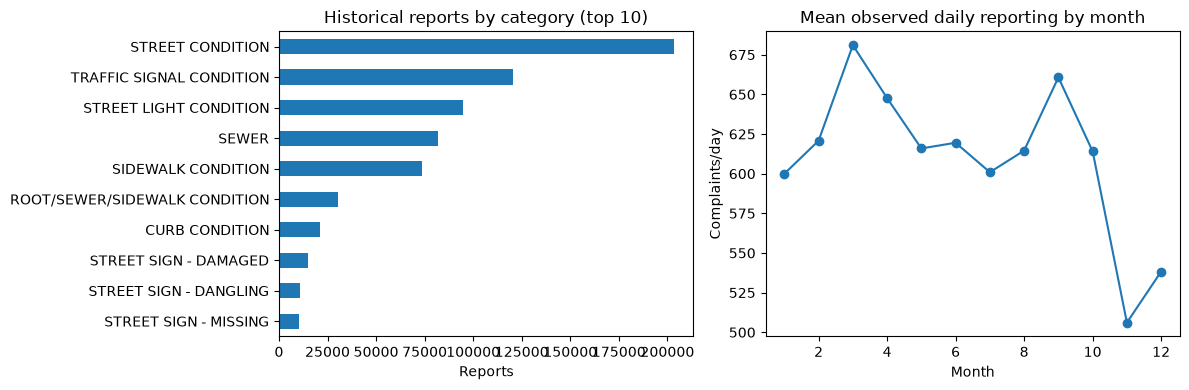

In [31]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Optional matplotlib is not installed; numerical EDA above remains available.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    category_summary.head(10).iloc[::-1].plot.barh(
        x="complaint_category", y="reports", ax=axes[0], legend=False)
    axes[0].set_title("Historical reports by category (top 10)")
    axes[0].set_xlabel("Reports")
    axes[0].set_ylabel("")
    month_profile["mean"].plot(ax=axes[1], marker="o")
    axes[1].set_title("Mean observed daily reporting by month")
    axes[1].set_xlabel("Month")
    axes[1].set_ylabel("Complaints/day")
    plt.tight_layout()
    plt.show()

## Design the historical comparison windows

A weekday-matched reference avoids directly comparing a Monday with a Sunday. The **seasonal** window further restricts history to the reporting month and adjacent months across prior years. A **broad** window uses all earlier matching weekdays.

Both windows exclude any date on or after the incoming reporting day to avoid information leakage. Support requires at least 8 historical complaints, 5 active days and 2 distinct years by default.

In [32]:
def comparison_windows(calendar, reporting_day):
    target = pd.Timestamp(reporting_day)
    prior = calendar[(calendar < target) & (calendar.weekday == target.weekday())]
    months = {((target.month - 2) % 12) + 1, target.month, (target.month % 12) + 1}
    seasonal = prior[np.isin(prior.month, sorted(months))]
    return seasonal, prior

seasonal_dates, broad_dates = comparison_windows(historical_calendar, REPORTING_DAY)
print("Example reporting date:", REPORTING_DAY, "weekday", pd.Timestamp(REPORTING_DAY).day_name())
print("Seasonal weekday dates:", len(seasonal_dates))
print("All comparable weekday dates:", len(broad_dates))
print("Seasonal months:", sorted(set(seasonal_dates.month)))
assert max(broad_dates) < pd.Timestamp(REPORTING_DAY)

Example reporting date: 2026-11-09 weekday Monday
Seasonal weekday dates: 39
All comparable weekday dates: 157
Seasonal months: [10, 11, 12]


### Baseline features for one historical area/category

An ordinary comparison row includes observed daily mean, 95th percentile, maximum count, days of historical activity, historical report total, and distinct reporting years. **Never classify unsupported history as a strong candidate.**

In [33]:
def reference_evidence(counts, area, category, days, min_reports=8, min_active_days=5, min_years=2):
    values = np.asarray([counts.get((area, category, d.strftime("%Y-%m-%d")), 0)
                         for d in days], dtype=int)
    active = values > 0
    years = int(len(set(days.year[active])))
    return {
        "calendar_days": int(len(days)), "historical_reports": int(values.sum()),
        "active_days": int(active.sum()), "years": years,
        "mean": float(values.mean()) if len(values) else 0.0,
        "p95": float(np.quantile(values, 0.95)) if len(values) else 0.0,
        "max": int(values.max()) if len(values) else 0,
        "supported": bool(int(values.sum()) >= min_reports and
                          int(active.sum()) >= min_active_days and years >= min_years),
    }

lead = historical_snapshot.groupby(["area_id", "complaint_category"])["complaint_count"].sum().idxmax()
print("Illustrative historically supported pair:", lead)
print("Seasonal evidence:", reference_evidence(historical_daily_counts, *lead, seasonal_dates))
print("Broad evidence:", reference_evidence(historical_daily_counts, *lead, broad_dates))

Illustrative historically supported pair: ('STATEN ISLAND_10314', 'STREET CONDITION')
Seasonal evidence: {'calendar_days': 39, 'historical_reports': 94, 'active_days': 35, 'years': 3, 'mean': 2.41025641025641, 'p95': 6.100000000000001, 'max': 7, 'supported': True}
Broad evidence: {'calendar_days': 157, 'historical_reports': 611, 'active_days': 147, 'years': 3, 'mean': 3.8917197452229297, 'p95': 9.0, 'max': 22, 'supported': True}


## Candidate decision rules: baseline experiments

The experiments below explain *why* the final candidate rule requires more than merely exceeding a percentile.

We compare progressively stronger options:

- **Loose signal:** current reports exceed a seasonal 95th percentile.
- **Seasonal maximum:** current reports exceed the seasonal historical maximum.
- **Cross-window exceedance:** current reports exceed both seasonal and broad weekday maxima with adequate history.
- **Strengthened cross-window candidate (final):** at least 8 incoming reports, at least 3 more than **each** historical maximum, and at least 50% above **each** maximum (except when the maximum is zero).

The final rule is **exploratory and conservative**, not a calibrated statistical significance test.

In [34]:
def compare_rules(count, seasonal, broad, incoming_floor=8, excess_floor=3, relative_factor=1.5):
    if not seasonal["supported"] or not broad["supported"]:
        return {"p95_signal": False, "seasonal_max": False,
                "cross_window": False, "strong_candidate": False}
    seasonal_max, broad_max = seasonal["max"], broad["max"]
    over_both = count > seasonal_max and count > broad_max
    strong = (over_both and count >= incoming_floor and
              count - seasonal_max >= excess_floor and
              count - broad_max >= excess_floor and
              (seasonal_max == 0 or count >= relative_factor * seasonal_max) and
              (broad_max == 0 or count >= relative_factor * broad_max))
    return {"p95_signal": count > seasonal["p95"],
            "seasonal_max": count > seasonal_max,
            "cross_window": bool(over_both),
            "strong_candidate": bool(strong)}

# Purely illustrative cases; not claims about NYC complaint counts.
s = {"supported": True, "p95": 2.0, "max": 4}
b = {"supported": True, "p95": 3.0, "max": 6}
experiment = pd.DataFrame([
    {"new_reports": n, **compare_rules(n, s, b)} for n in (2, 5, 7, 8, 9, 10, 12)
])
print(experiment.to_string(index=False))
assert not compare_rules(8, s, b)["strong_candidate"]
assert compare_rules(10, s, b)["strong_candidate"]

 new_reports  p95_signal  seasonal_max  cross_window  strong_candidate
           2       False         False         False             False
           5        True          True         False             False
           7        True          True          True             False
           8        True          True          True             False
           9        True          True          True              True
          10        True          True          True              True
          12        True          True          True              True


### 6.1 — Select the final model rule

The final method preserves **other review states**: no historical coverage, insufficient historical support, reference-window sensitivity, above-percentile signals, and maxima exceeded without the required strength. The **candidate set** consists only of `cross_window_consistent_candidate` rows.

A complete report also retains the row-by-row reasons why incoming records were excluded. That requires a trustworthy selected-day and geographic-validation contract.

## Implement reporting-day selection from first principles

Incoming timestamps are normalized to the **America/New_York** reporting day, explicitly handling timezone offsets and rejecting ambiguous/nonexistent local DST times. This function is *defined in this notebook*: no existing model or engine import is necessary.

In [35]:
"""Select one NYC-local reporting day from an incoming batch.

Naive timestamps are interpreted as New York local
time. Explicit timestamp offsets are converted to
New York time.

Ambiguous/nonexistent local DST times are rejected.
All original records remain auditable.
"""

from datetime import date, datetime
import pandas as pd


NYC_TIMEZONE = "America/New_York"


def _parse_nyc_day(value):
    """Return (NYC day, parsing status)."""

    if pd.isna(value):
        return None, "invalid_or_missing_date"

    text = str(value).strip()

    if not text:
        return None, "invalid_or_missing_date"

    parsed = None

    try:
        parsed = datetime.fromisoformat(
            text.replace("Z", "+00:00")
        )
    except ValueError:
        pass

    if parsed is None:

        for fmt in [
            "%m/%d/%Y %I:%M:%S %p",
            "%m/%d/%Y %H:%M:%S"
        ]:
            try:
                parsed = datetime.strptime(
                    text, fmt
                )
                break
            except ValueError:
                continue

    if parsed is None:
        return None, "invalid_or_missing_date"

    try:
        timestamp = pd.Timestamp(parsed)

        if timestamp.tzinfo is None:

            timestamp = timestamp.tz_localize(
                NYC_TIMEZONE,
                ambiguous="NaT",
                nonexistent="NaT"
            )

            parse_status = "assumed_nyc_local"

        else:

            timestamp = timestamp.tz_convert(
                NYC_TIMEZONE
            )

            parse_status = "converted_timezone"

        if pd.isna(timestamp):
            return None, "invalid_or_missing_date"

        return (
            timestamp.date().isoformat(),
            parse_status
        )

    except (ValueError, TypeError, OverflowError):
        return None, "invalid_or_missing_date"


def select_daily_complaints(
    records,
    reporting_day
):
    """Select an explicit NYC reporting day.

    Returns selected records plus a row-level audit.
    Does not mutate the input DataFrame.
    """

    if not isinstance(records, pd.DataFrame):
        raise TypeError("Expected a DataFrame.")

    required = {
        "source_row",
        "complaint_id",
        "created_date"
    }

    missing = required - set(records.columns)

    if missing:
        raise ValueError(
            f"Missing columns: {sorted(missing)}"
        )

    if records["source_row"].duplicated().any():
        raise ValueError(
            "Duplicate source_row values."
        )

    if not isinstance(reporting_day, str):
        raise ValueError(
            "reporting_day must be YYYY-MM-DD."
        )

    try:
        target = date.fromisoformat(
            reporting_day
        ).isoformat()
    except ValueError as exc:
        raise ValueError(
            "Invalid reporting day."
        ) from exc

    if target != reporting_day:
        raise ValueError(
            "Use YYYY-MM-DD reporting day."
        )

    work = records.copy().reset_index(drop=True)

    parsed = [
        _parse_nyc_day(value)
        for value in work["created_date"]
    ]

    work["nyc_reporting_day"] = [
        item[0] for item in parsed
    ]

    work["date_parse_status"] = [
        item[1] for item in parsed
    ]

    work["daily_window_status"] = (
        "outside_selected_day"
    )

    invalid = work["nyc_reporting_day"].isna()

    work.loc[
        invalid,
        "daily_window_status"
    ] = "invalid_or_missing_date"

    selected = work[
        "nyc_reporting_day"
    ].eq(target).fillna(False)

    work.loc[
        selected,
        "daily_window_status"
    ] = "selected_day"

    # Select from the original records, preserving
    # original model input columns and row order.
    selected_records = (
        records.reset_index(drop=True)
        .loc[selected.to_numpy()]
        .copy()
    )

    audit_columns = [
        "source_row",
        "complaint_id",
        "created_date",
        "nyc_reporting_day",
        "date_parse_status",
        "daily_window_status"
    ]

    audit = work[audit_columns].copy()

    stats = {
        "reporting_day": target,
        "timezone": NYC_TIMEZONE,
        "input_records": int(len(work)),
        "selected_records": int(selected.sum()),
        "outside_selected_day": int(
            work["daily_window_status"].eq(
                "outside_selected_day"
            ).sum()
        ),
        "invalid_or_missing_date": int(
            invalid.sum()
        ),
        "naive_local_assumptions": int(
            work["date_parse_status"].eq(
                "assumed_nyc_local"
            ).sum()
        ),
        "timezone_conversions": int(
            work["date_parse_status"].eq(
                "converted_timezone"
            ).sum()
        )
    }

    assert (
        stats["selected_records"]
        + stats["outside_selected_day"]
        + stats["invalid_or_missing_date"]
    ) == stats["input_records"]

    return {
        "selected_records": selected_records,
        "audit": audit,
        "stats": stats
    }

## Implement the final anomaly-screening engine

This is the full, reusable reference implementation of the chosen **historical-versus-incoming screening algorithm**. It computes seasonal and broad reference evidence, applies the strengthened threshold, returns all comparison rows and candidate groups, and retains a row-level audit.

The implementation below is self-contained apart from Python data libraries and the selector defined above. It accepts *already processed, geographically validated* records. It does **not** assert that arbitrary raw coordinates have been validated.

In [36]:
"""Exploratory historical-versus-incoming complaint screen.

Uses weekday-matched daily count references.
Screening candidates are not confirmed anomalies,
statistical significance claims, or repair priorities.

Historical area coverage must be explicitly supplied.
"""

import re
import numpy as np
import pandas as pd



VALID_BOROUGHS = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
}


def _window_evidence(
    daily_counts,
    area_id,
    category,
    dates,
    min_historical_reports,
    min_active_days,
    min_years
):
    labels = dates.strftime("%Y-%m-%d")

    values = np.array([
        int(daily_counts.get(
            (area_id, category, day),
            0
        ))
        for day in labels
    ], dtype=np.int64)

    active = values > 0

    years = len(set(
        dates.year[active].tolist()
    ))

    total = int(values.sum())
    active_days = int(active.sum())

    supported = (
        total >= min_historical_reports
        and active_days >= min_active_days
        and years >= min_years
    )

    return {
        "calendar_days": len(values),
        "reports": total,
        "active_days": active_days,
        "years_with_reports": years,
        "supported": bool(supported),
        "mean": (
            float(values.mean())
            if len(values) else 0.0
        ),
        "p95": (
            float(np.quantile(values, 0.95))
            if len(values) else 0.0
        ),
        "maximum": (
            int(values.max())
            if len(values) else 0
        )
    }


def screen_daily_anomalies(
    records,
    supported_categories,
    historical_daily_counts,
    historical_calendar,
    historical_area_ids,
    reporting_day,
    min_incoming_reports=8,
    min_historical_reports=8,
    min_active_days=5,
    min_years=2
):
    """Return exploratory anomaly evidence and row audit.

    Only processed, ZIP-consistent complaints
    belonging to the selected NYC reporting day
    enter the area/category count comparison.
    """

    required = {
        "source_row",
        "complaint_id",
        "created_date",
        "processing_status",
        "zip_validation_status",
        "borough",
        "incident_zip",
        "complaint_category"
    }

    if not isinstance(records, pd.DataFrame):
        raise TypeError("records must be a DataFrame")

    if records.columns.duplicated().any():
        raise ValueError("Duplicate column names")

    missing = required - set(records.columns)

    if missing:
        raise ValueError(
            f"Missing columns: {sorted(missing)}"
        )

    if min_incoming_reports < 1:
        raise ValueError(
            "min_incoming_reports must be positive"
        )

    categories = {
        str(x).strip().upper()
        for x in supported_categories
    }

    known_areas = {
        str(x).strip().upper()
        for x in historical_area_ids
    }

    if not re.fullmatch(
        r"\d{4}-\d{2}-\d{2}",
        str(reporting_day)
    ):
        raise ValueError("Use YYYY-MM-DD")

    daily = select_daily_complaints(
        records,
        reporting_day
    )

    selected = daily[
        "selected_records"
    ].copy().reset_index(drop=True)

    borough = (
        selected["borough"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    zip_code = (
        selected["incident_zip"]
        .astype(str)
        .str.strip()
    )

    category = (
        selected["complaint_category"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    processed = selected[
        "processing_status"
    ].astype(str).eq("processed")

    zip_consistent = selected[
        "zip_validation_status"
    ].astype(str).eq("zcta_consistent")

    valid_borough = borough.isin(
        VALID_BOROUGHS
    )

    valid_zip = zip_code.str.fullmatch(
        r"\d{5}",
        na=False
    )

    supported = category.isin(
        categories
    )

    # Order of conditions gives a single
    # auditable reason per excluded record.
    reasons = np.select(
        [
            ~processed,
            ~zip_consistent,
            ~valid_borough,
            ~valid_zip,
            ~supported
        ],
        [
            "not_processed",
            "zip_not_verified",
            "invalid_borough",
            "invalid_zip",
            "unsupported_category"
        ],
        default="eligible"
    )

    selected["anomaly_input_status"] = reasons

    selected["area_id"] = (
        borough + "_" + zip_code
    )

    selected["complaint_category"] = category

    eligible = selected.loc[
        selected["anomaly_input_status"].eq(
            "eligible"
        )
    ].copy()

    incoming_counts = (
        eligible.groupby(
            ["area_id", "complaint_category"]
        )
        .size()
        .rename("incoming_reports")
        .reset_index()
    )

    # Do not include historical reference days
    # that occur on or after the reporting day.
    dates = pd.DatetimeIndex(
        pd.to_datetime(
            list(historical_calendar)
        )
    ).normalize().unique().sort_values()

    if dates.tz is not None:
        raise ValueError(
            "Historical calendar must use local dates"
        )

    target = pd.Timestamp(reporting_day)

    all_weekdays = dates[
        (dates < target)
        & (dates.weekday == target.weekday())
    ]

    # Three-month comparison window centered
    # on the reporting month, wrapping years.
    seasonal_months = {
        ((target.month - 2) % 12) + 1,
        target.month,
        (target.month % 12) + 1
    }

    seasonal = all_weekdays[
        np.isin(
            all_weekdays.month,
            list(seasonal_months)
        )
    ]

    rows = []

    for item in incoming_counts.itertuples(
        index=False
    ):

        area = str(item.area_id)
        complaint_category = str(
            item.complaint_category
        )

        count = int(item.incoming_reports)

        seasonal_ev = _window_evidence(
            historical_daily_counts,
            area,
            complaint_category,
            seasonal,
            min_historical_reports,
            min_active_days,
            min_years
        )

        broad_ev = _window_evidence(
            historical_daily_counts,
            area,
            complaint_category,
            all_weekdays,
            min_historical_reports,
            min_active_days,
            min_years
        )

        area_known = area in known_areas

        # Raw candidate flags are retained solely
        # for audit and threshold comparison.
        seasonal_raw_5 = (
            area_known
            and seasonal_ev["supported"]
            and count >= 5
            and count > seasonal_ev["maximum"]
        )

        broad_raw_5 = (
            area_known
            and broad_ev["supported"]
            and count >= 5
            and count > broad_ev["maximum"]
        )

        seasonal_above_max = (
            count > seasonal_ev["maximum"]
        )

        broad_above_max = (
            count > broad_ev["maximum"]
        )

        if not area_known:

            review_status = (
                "no_historical_area_coverage"
            )

        elif not seasonal_ev["supported"]:

            review_status = (
                "insufficient_historical_support"
            )

        # PHASE 23.3 — STRONG HISTORICAL EXCEEDANCE
        #
        # Require at least 3 extra reports AND
        # at least 50% above each historical maximum.
        #
        # A historical maximum of zero does not
        # require a percentage calculation.
        # Existing history-support checks still apply.

        elif (
            count >= min_incoming_reports
            and broad_ev["supported"]
            and seasonal_above_max
            and broad_above_max
            and (count - seasonal_ev["maximum"]) >= 3
            and (
                seasonal_ev["maximum"] == 0
                or count >= 1.5 * seasonal_ev["maximum"]
            )
            and (count - broad_ev["maximum"]) >= 3
            and (
                broad_ev["maximum"] == 0
                or count >= 1.5 * broad_ev["maximum"]
            )
        ):

            review_status = (
                "cross_window_consistent_candidate"
            )

        # A count may exceed historical maxima
        # without meeting the stronger threshold.
        # Do not classify it as an anomaly candidate.

        elif (
            count >= min_incoming_reports
            and broad_ev["supported"]
            and seasonal_above_max
            and broad_above_max
        ):

            review_status = (
                "historical_max_exceeded_below_strength_threshold"
            )

        elif (
            count >= min_incoming_reports
            and seasonal_above_max
        ):

            review_status = (
                "reference_window_sensitive_review"
            )

        elif seasonal_above_max:

            review_status = (
                "above_seasonal_max_below_report_floor"
            )

        elif count > seasonal_ev["p95"]:

            review_status = "above_seasonal_p95"

        else:

            review_status = (
                "within_matched_historical_range"
            )

        rows.append({
            "reporting_day": reporting_day,
            "area_id": area,
            "complaint_category":
                complaint_category,
            "incoming_reports": count,
            "historical_area_covered": area_known,
            "seasonal_days":
                seasonal_ev["calendar_days"],
            "seasonal_historical_reports":
                seasonal_ev["reports"],
            "seasonal_active_days":
                seasonal_ev["active_days"],
            "seasonal_years_with_reports":
                seasonal_ev["years_with_reports"],
            "seasonal_support":
                seasonal_ev["supported"],
            "seasonal_daily_mean":
                seasonal_ev["mean"],
            "seasonal_daily_p95":
                seasonal_ev["p95"],
            "seasonal_daily_max":
                seasonal_ev["maximum"],
            "all_weekday_days":
                broad_ev["calendar_days"],
            "all_weekday_support":
                broad_ev["supported"],
            "all_weekday_daily_max":
                broad_ev["maximum"],
            "seasonal_candidate_floor_5":
                bool(seasonal_raw_5),
            "all_weekday_candidate_floor_5":
                bool(broad_raw_5),
            "anomaly_review_status":
                review_status
        })

    comparisons = pd.DataFrame(rows)

    # Ensure a stable schema when input is empty.
    if comparisons.empty:
        comparisons = pd.DataFrame(columns=[
            "reporting_day",
            "area_id",
            "complaint_category",
            "incoming_reports",
            "historical_area_covered",
            "seasonal_days",
            "seasonal_historical_reports",
            "seasonal_active_days",
            "seasonal_years_with_reports",
            "seasonal_support",
            "seasonal_daily_mean",
            "seasonal_daily_p95",
            "seasonal_daily_max",
            "all_weekday_days",
            "all_weekday_support",
            "all_weekday_daily_max",
            "seasonal_candidate_floor_5",
            "all_weekday_candidate_floor_5",
            "anomaly_review_status"
        ])

    quality_audit = selected[[
        "source_row",
        "anomaly_input_status"
    ]]

    eligible_review = (
        eligible[[
            "source_row",
            "area_id",
            "complaint_category"
        ]]
        .merge(
            comparisons[[
                "area_id",
                "complaint_category",
                "anomaly_review_status"
            ]],
            on=[
                "area_id",
                "complaint_category"
            ],
            how="left",
            validate="many_to_one"
        )[[
            "source_row",
            "anomaly_review_status"
        ]]
    )

    record_audit = (
        daily["audit"]
        .merge(
            quality_audit,
            on="source_row",
            how="left",
            validate="one_to_one"
        )
        .merge(
            eligible_review,
            on="source_row",
            how="left",
            validate="one_to_one"
        )
    )

    record_audit[
        "anomaly_input_status"
    ] = record_audit[
        "anomaly_input_status"
    ].fillna("not_in_reporting_day")

    record_audit[
        "anomaly_review_status"
    ] = record_audit[
        "anomaly_review_status"
    ].fillna("not_analyzed")

    candidates = comparisons.loc[
        comparisons["anomaly_review_status"].eq(
            "cross_window_consistent_candidate"
        )
    ].copy()

    stats = {
        "input_records": int(len(records)),
        "selected_records": int(len(selected)),
        "date_exclusions": int(
            len(records) - len(selected)
        ),
        "eligible_records": int(len(eligible)),
        "quality_exclusions": int(
            len(selected) - len(eligible)
        ),
        "active_area_category_combinations":
            int(len(comparisons)),
        "candidate_combinations":
            int(len(candidates)),
        "candidate_complaints": (
            int(candidates[
                "incoming_reports"
            ].sum())
            if not candidates.empty else 0
        ),
        "seasonal_reference_days":
            int(len(seasonal)),
        "all_weekday_reference_days":
            int(len(all_weekdays))
    }

    if (
        stats["date_exclusions"]
        + stats["quality_exclusions"]
        + stats["eligible_records"]
        != stats["input_records"]
    ):
        raise AssertionError(
            "Input coverage did not reconcile"
        )

    if (
        int(comparisons[
            "incoming_reports"
        ].sum()) != len(eligible)
    ):
        raise AssertionError(
            "Incoming comparison counts disagree"
        )

    if len(record_audit) != len(records):
        raise AssertionError(
            "Record audit lost source records"
        )

    return {
        "comparisons": comparisons,
        "candidates": candidates,
        "record_audit": record_audit,
        "stats": stats,
        "parameters": {
            "reporting_day": reporting_day,
            "min_incoming_reports":
                min_incoming_reports,
            "min_historical_reports":
                min_historical_reports,
            "min_active_days": min_active_days,
            "min_years": min_years,
            "seasonal_months":
                sorted(seasonal_months),
            "screening_only": True
        }
    }

## Controlled synthetic unit experiment

Construct a **synthetic** reference and synthetic processed rows *only for testing the anomaly algorithm*. The synthetic processing/ZIP statuses are test fixtures; no geographic validation is being claimed. This experiment proves that a strong increase is selected, an unsupported category is excluded, and a record outside the selected day is audited.

In [37]:
def make_synthetic_fixture(reporting_day=REPORTING_DAY):
    target = pd.Timestamp(reporting_day)
    calendar = pd.date_range(START_DAY, END_DAY, freq="D")
    sample_days = calendar[(calendar.weekday == target.weekday()) &
                           np.isin(calendar.month, [10, 11, 12])]
    per_year = [sample_days[sample_days.year == year][:8] for year in (2023, 2024, 2025)]
    hist = {("MANHATTAN_10001", "STREET CONDITION", date.strftime("%Y-%m-%d")): 1
            for group in per_year for date in group}
    assert len(hist) >= 15
    rows = []
    for i in range(20):
        rows.append({"source_row": i, "complaint_id": f"SYN-{i:03d}",
                     "created_date": reporting_day, "processing_status": "processed",
                     "zip_validation_status": "zcta_consistent", "borough": "MANHATTAN",
                     "incident_zip": "10001", "complaint_category": "STREET CONDITION"})
    rows.append({"source_row": 20, "complaint_id": "SYN-OFF-DAY",
                 "created_date": "2026-11-10", "processing_status": "processed",
                 "zip_validation_status": "zcta_consistent", "borough": "MANHATTAN",
                 "incident_zip": "10001", "complaint_category": "STREET CONDITION"})
    rows.append({"source_row": 21, "complaint_id": "SYN-BAD-ZIP",
                 "created_date": reporting_day, "processing_status": "processed",
                 "zip_validation_status": "zcta_mismatch", "borough": "MANHATTAN",
                 "incident_zip": "10001", "complaint_category": "STREET CONDITION"})
    return pd.DataFrame(rows), hist, calendar, ["MANHATTAN_10001"]

fixture, fixture_counts, fixture_calendar, fixture_areas = make_synthetic_fixture()
fixture_result = screen_daily_anomalies(
    records=fixture, supported_categories=["STREET CONDITION"],
    historical_daily_counts=fixture_counts, historical_calendar=fixture_calendar,
    historical_area_ids=fixture_areas, reporting_day=REPORTING_DAY,
)
print("Synthetic fixture stats:", fixture_result["stats"])
print(fixture_result["comparisons"].to_string(index=False))
assert fixture_result["stats"]["candidate_combinations"] == 1
assert fixture_result["stats"]["candidate_complaints"] == 20
assert len(fixture_result["record_audit"]) == len(fixture)
assert fixture_result["stats"]["date_exclusions"] == 1
assert fixture_result["stats"]["quality_exclusions"] == 1
print("PASS: synthetic elevated-reporting and exclusion tests")

Synthetic fixture stats: {'input_records': 22, 'selected_records': 21, 'date_exclusions': 1, 'eligible_records': 20, 'quality_exclusions': 1, 'active_area_category_combinations': 1, 'candidate_combinations': 1, 'candidate_complaints': 20, 'seasonal_reference_days': 39, 'all_weekday_reference_days': 157}
reporting_day         area_id complaint_category  incoming_reports  historical_area_covered  seasonal_days  seasonal_historical_reports  seasonal_active_days  seasonal_years_with_reports  seasonal_support  seasonal_daily_mean  seasonal_daily_p95  seasonal_daily_max  all_weekday_days  all_weekday_support  all_weekday_daily_max  seasonal_candidate_floor_5  all_weekday_candidate_floor_5             anomaly_review_status
   2026-11-09 MANHATTAN_10001   STREET CONDITION                20                     True             39                           24                    24                            3              True             0.615385                 1.0                   1         

###  Negative controls and input-contract tests

A useful research notebook must test when the model should **not** flag a candidate, not just when it should. This includes counts below the reporting threshold, insufficient history, and duplicate source-row IDs.

In [38]:
negative = fixture.iloc[:6].copy()
negative_result = screen_daily_anomalies(
    negative, ["STREET CONDITION"], fixture_counts, fixture_calendar,
    fixture_areas, REPORTING_DAY
)
assert negative_result["stats"]["candidate_combinations"] == 0
assert negative_result["stats"]["candidate_complaints"] == 0

no_history = screen_daily_anomalies(
    fixture.iloc[:20], ["STREET CONDITION"], {}, fixture_calendar,
    [], REPORTING_DAY
)
assert no_history["stats"]["candidate_combinations"] == 0
assert (no_history["comparisons"]["anomaly_review_status"] == "no_historical_area_coverage").all()

bad = fixture.iloc[:5].copy()
bad.loc[bad.index[1], "source_row"] = bad.loc[bad.index[0], "source_row"]
try:
    screen_daily_anomalies(bad, ["STREET CONDITION"], fixture_counts,
                           fixture_calendar, fixture_areas, REPORTING_DAY)
except ValueError:
    pass
else:
    raise AssertionError("Duplicate source row was not rejected")

print("PASS: below-threshold, no-coverage, and duplicate-ID controls")

PASS: below-threshold, no-coverage, and duplicate-ID controls


## Real historical baseline + verified demonstration batch

Now reuse the **baseline we built from scratch in the historical data preparation section**, and optionally evaluate the pre-existing *processed* 500-row demonstration CSV from the project's tests. Unlike the synthetic unit experiment, this stage requires the project files and preserves the backend validation statuses already assigned to those records.

**Do not pass arbitrary raw CSV data here:** the anomaly function expects `processing_status` and `zip_validation_status` from the existing geographic-validation stage.

In [39]:
SCREEN_INPUT = TEST_BATCH
processed_demo = None
screen_result = None
if not SCREEN_INPUT.is_file():
    print("Optional verified demonstration file is unavailable:", SCREEN_INPUT)
    print("Complete baseline construction and synthetic model tests are still valid.")
else:
    processed_demo = pd.read_csv(SCREEN_INPUT, dtype={"incident_zip": "string"}, low_memory=False)
    mandatory = {"source_row", "complaint_id", "created_date", "processing_status",
                 "zip_validation_status", "borough", "incident_zip", "complaint_category"}
    absent = mandatory - set(processed_demo)
    if absent:
        raise ValueError(f"Processed demo lacks columns {sorted(absent)}")
    print("Processed demonstration complaints:", len(processed_demo))
    print("Processing status counts:")
    print(processed_demo["processing_status"].value_counts(dropna=False).to_string())
    screen_result = screen_daily_anomalies(
        processed_demo, supported_categories, historical_daily_counts,
        historical_calendar, historical_area_ids, REPORTING_DAY
    )
    print("Screening stats:", screen_result["stats"])
    print(screen_result["candidates"].head(15).to_string(index=False))

Processed demonstration complaints: 500
Processing status counts:
processing_status
processed    500
Screening stats: {'input_records': 500, 'selected_records': 500, 'date_exclusions': 0, 'eligible_records': 500, 'quality_exclusions': 0, 'active_area_category_combinations': 100, 'candidate_combinations': 10, 'candidate_complaints': 139, 'seasonal_reference_days': 39, 'all_weekday_reference_days': 157}
reporting_day             area_id     complaint_category  incoming_reports  historical_area_covered  seasonal_days  seasonal_historical_reports  seasonal_active_days  seasonal_years_with_reports  seasonal_support  seasonal_daily_mean  seasonal_daily_p95  seasonal_daily_max  all_weekday_days  all_weekday_support  all_weekday_daily_max  seasonal_candidate_floor_5  all_weekday_candidate_floor_5             anomaly_review_status
   2026-11-09         BRONX_10451       STREET CONDITION                14                     True             39                           27                    16 

### 10.1 — Row-level audit and review statuses

The model does not silently drop rows. Inspect `record_audit`, `comparisons`, and candidate status frequencies to understand which inputs were accepted or rejected.

In [40]:
if screen_result is not None:
    print("Input audit statuses:")
    print(screen_result["record_audit"]["anomaly_input_status"].value_counts(dropna=False).to_string())
    print("\nArea/category anomaly review statuses:")
    print(screen_result["comparisons"]["anomaly_review_status"].value_counts(dropna=False).to_string())
    assert len(screen_result["record_audit"]) == len(processed_demo)
    assert screen_result["stats"]["input_records"] == len(processed_demo)
else:
    print("Optional processed demonstration not supplied; use the fixture tests above.")

Input audit statuses:
anomaly_input_status
eligible    500

Area/category anomaly review statuses:
anomaly_review_status
insufficient_historical_support                     35
within_matched_historical_range                     26
above_seasonal_p95                                  12
above_seasonal_max_below_report_floor               11
cross_window_consistent_candidate                   10
historical_max_exceeded_below_strength_threshold     5
reference_window_sensitive_review                    1


## Hyperparameter and threshold sensitivity

As in K-Means model selection and DBSCAN radius experiments, anomaly screening needs **threshold comparisons**. These do not establish a universally optimal threshold without labeled anomalies; they show how conservative choices affect the number of candidate groups.

Compare candidate strength with incoming floors of 5, 8 and 10, absolute exceedance floors of 2, 3 and 5, and relative multipliers of 1.25, 1.50 and 2.00.

In [41]:
from itertools import product

# Use actual area/category historical maxima computed from the model, if available.
# Otherwise the synthetic fixture demonstrates the same threshold mechanics.
if screen_result is not None and len(screen_result["comparisons"]):
    study_frame = screen_result["comparisons"].copy()
else:
    study_frame = fixture_result["comparisons"].copy()

records = []
for floor, excess, ratio in product([5, 8, 10], [2, 3, 5], [1.25, 1.5, 2.0]):
    matches = []
    for row in study_frame.itertuples(index=False):
        smax = float(row.seasonal_daily_max)
        bmax = float(row.all_weekday_daily_max)
        count = int(row.incoming_reports)
        passes = (
            bool(row.historical_area_covered) and bool(row.seasonal_support)
            and bool(row.all_weekday_support)
            and count >= floor and count > smax and count > bmax
            and count - smax >= excess and count - bmax >= excess
            and (smax == 0 or count >= ratio * smax)
            and (bmax == 0 or count >= ratio * bmax)
        )
        matches.append(passes)
    records.append({"incoming_floor": floor, "absolute_excess": excess,
                    "relative_multiplier": ratio, "candidate_groups": int(sum(matches))})
parameter_comparison = pd.DataFrame(records).sort_values(
    ["incoming_floor", "absolute_excess", "relative_multiplier"]
).reset_index(drop=True)
print(parameter_comparison.to_string(index=False))
print("\nCurrent reference: 8 incoming reports, +3 above both maxima, 1.5× both maxima.")

 incoming_floor  absolute_excess  relative_multiplier  candidate_groups
              5                2                 1.25                17
              5                2                 1.50                14
              5                2                 2.00                 8
              5                3                 1.25                14
              5                3                 1.50                11
              5                3                 2.00                 8
              5                5                 1.25                10
              5                5                 1.50                10
              5                5                 2.00                 8
              8                2                 1.25                13
              8                2                 1.50                10
              8                2                 2.00                 8
              8                3                 1.25           

### 11.1 — Visualize candidate-count sensitivity

The plot shows **screening volume**, not model accuracy or reliability of infrastructure repairs.

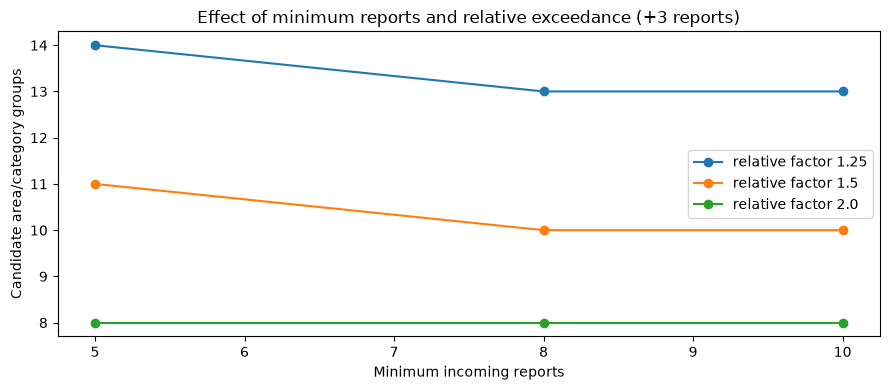

In [42]:
if "plt" in globals():
    sub = parameter_comparison.loc[parameter_comparison["absolute_excess"].eq(3)]
    fig, ax = plt.subplots(figsize=(9, 4))
    for relative_factor, group in sub.groupby("relative_multiplier"):
        group.sort_values("incoming_floor").plot.line(
            x="incoming_floor", y="candidate_groups", marker="o",
            ax=ax, label=f"relative factor {relative_factor}")
    ax.set_title("Effect of minimum reports and relative exceedance (+3 reports)")
    ax.set_xlabel("Minimum incoming reports")
    ax.set_ylabel("Candidate area/category groups")
    plt.tight_layout()
    plt.show()
else:
    print("Optional matplotlib missing; threshold table above contains the full results.")

## Historical backtesting without future leakage

A retrospective experiment treats selected **2025 historical reporting days** as pseudo-incoming days, using **only earlier dates** as the reference. We report how often the rule triggers among supported area/categories; we do **not** call those flags true or false positives because there are no verified anomaly labels.

This is a **historical alert-rate audit**, not a supervised validation benchmark. It never uses records from later dates when constructing each day’s comparison windows.

In [43]:
# Bound the retrospective study for notebook runtime: top 12 historically active area/categories,
# one comparable weekday per month in 2025. All samples are deterministic.
leaders = (historical_snapshot.groupby(["area_id", "complaint_category"])["complaint_count"]
           .sum().sort_values(ascending=False).head(12).index.tolist())
backtest_days = pd.date_range("2025-01-01", "2025-12-31", freq="MS") + pd.Timedelta(days=7)
backtest_rows = []
for check_day in backtest_days:
    season, broad = comparison_windows(historical_calendar, check_day.strftime("%Y-%m-%d"))
    for area, category in leaders:
        incoming = int(historical_daily_counts.get((area, category, check_day.strftime("%Y-%m-%d")), 0))
        a = reference_evidence(historical_daily_counts, area, category, season)
        b = reference_evidence(historical_daily_counts, area, category, broad)
        flags = compare_rules(incoming, a, b)
        backtest_rows.append({"date": check_day.strftime("%Y-%m-%d"), "area": area,
                              "category": category, "incoming": incoming,
                              "historically_supported": a["supported"] and b["supported"],
                              **flags})
backtest = pd.DataFrame(backtest_rows)
print("Retrospective checks:", len(backtest))
print("Supported comparisons:", int(backtest["historically_supported"].sum()))
print("Strong screening signals:", int(backtest["strong_candidate"].sum()))
if bool(backtest["historically_supported"].any()):
    n_support = int(backtest["historically_supported"].sum())
    n_signal = int(backtest.loc[backtest["historically_supported"], "strong_candidate"].sum())
    print("Observed alert frequency among supported cases:", f"{n_signal}/{n_support}")
print("Note: no anomaly ground-truth labels or accuracy estimates are implied.")

Retrospective checks: 144
Supported comparisons: 144
Strong screening signals: 0
Observed alert frequency among supported cases: 0/144
Note: no anomaly ground-truth labels or accuracy estimates are implied.


## Deployment design and reproducibility contract

The research method has two reusable parts:

1. **Historical reference data** (sparse daily count CSV + JSON manifest with taxonomy, dates, counts and provenance).
2. **Screening engine** implementing validation, day selection, history-support evidence, cross-window candidate rules, and row auditing.

This notebook **develops these components independently**. In your existing application, a compatible production module is `src/models/new_batch_anomaly_screen.py` and the snapshot is loaded through `src/integration/anomaly_snapshot_integration.py`. These are downstream deployment counterparts; they are **not imported to construct or run this notebook's algorithm**.

The workflow must not be mistaken for training an IsolationForest or another supervised model. The “model artifact” is the reference plus the deterministic rule specification.

In [44]:
observed_categories = sorted(set(historical_snapshot["complaint_category"].astype(str)))
reference_manifest = {
    "model_family": "historical_weekday_and_seasonal_anomaly_screen",
    "study_period_start": START_DAY,
    "study_period_end": END_DAY,
    "historical_start": START_DAY,
    "historical_end": END_DAY,
    "calendar_days": int(len(historical_calendar)),
    "source": MASTER.relative_to(ROOT).as_posix(),
    "source_rows": int(audit["source_rows"]),
    "eligible_rows": int(audit["eligible_rows"]),
    "area_count": int(len(historical_area_ids)),
    "category_count": int(len(supported_categories)),
    "supported_categories": list(supported_categories),
    "observed_eligible_categories": observed_categories,
    "categories_without_eligible_area_records": sorted(set(supported_categories) - set(observed_categories)),
    "sparse_daily_entries": int(len(historical_snapshot)),
    "schema": ["area_id", "complaint_category", "historical_day", "complaint_count"],
    "screening_defaults": {"min_incoming_reports": 8, "min_historical_reports": 8,
                           "min_active_days": 5, "min_years": 2, "absolute_excess": 3,
                           "relative_excess_factor": 1.5},
    "interpretation": "Exploratory reporting anomaly evidence only; not verified infrastructure damage"
}
print(json.dumps(reference_manifest, indent=2))

{
  "model_family": "historical_weekday_and_seasonal_anomaly_screen",
  "study_period_start": "2023-01-01",
  "study_period_end": "2025-12-31",
  "historical_start": "2023-01-01",
  "historical_end": "2025-12-31",
  "calendar_days": 1096,
  "source": "data/processed/nyc311_infrastructure_cleaned.csv",
  "source_rows": 685284,
  "eligible_rows": 668440,
  "area_count": 238,
  "category_count": 15,
  "supported_categories": [
    "BRIDGE CONDITION",
    "CURB CONDITION",
    "ROOT/SEWER/SIDEWALK CONDITION",
    "SEWER",
    "SEWER MAINTENANCE",
    "SIDEWALK CONDITION",
    "STREET CONDITION",
    "STREET LIGHT CONDITION",
    "STREET SIGN - DAMAGED",
    "STREET SIGN - DANGLING",
    "STREET SIGN - MISSING",
    "TRAFFIC SIGNAL CONDITION",
    "WATER DRAINAGE",
    "WATER LEAK",
    "WATER MAINTENANCE"
  ],
  "observed_eligible_categories": [
    "CURB CONDITION",
    "ROOT/SEWER/SIDEWALK CONDITION",
    "SEWER",
    "SEWER MAINTENANCE",
    "SIDEWALK CONDITION",
    "STREET CONDITION",

### 13.1 — Optional compatibility test against the existing production module

This optional **read-only test** confirms the notebook's *result* agrees with the already-deployed Python module for the synthetic fixture. It is intentionally placed **after** construction and testing: the notebook is not built by importing the production engine.

In [45]:
from importlib import import_module
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
try:
    deployed = import_module("src.models.new_batch_anomaly_screen")
except (ModuleNotFoundError, ImportError) as exc:
    print("Optional production compatibility check skipped:", exc)
else:
    deployed_result = deployed.screen_daily_anomalies(
        fixture, ["STREET CONDITION"], fixture_counts, fixture_calendar,
        fixture_areas, REPORTING_DAY
    )
    fields = ["reporting_day", "area_id", "complaint_category", "incoming_reports", "anomaly_review_status"]
    mine = fixture_result["comparisons"][fields].sort_values(fields[:3]).reset_index(drop=True)
    theirs = deployed_result["comparisons"][fields].sort_values(fields[:3]).reset_index(drop=True)
    pd.testing.assert_frame_equal(mine, theirs, check_dtype=False)
    assert deployed_result["stats"] == fixture_result["stats"]
    print("PASS: notebook implementation agrees with deployed engine on controlled fixture")

PASS: notebook implementation agrees with deployed engine on controlled fixture


## Reproducible production-engine generation (without modifying the application)

This research notebook is the **source of the anomaly algorithm**. The application still imports the stable
`src/models/new_batch_anomaly_screen.py` interface. This phase regenerates that module from the
algorithm defined in the anomaly-screening implementation section. The only difference is that production imports the tested
NYC reporting-day selector from `src/integration/daily_batch_window.py`, rather than embedding a second copy.

The generated production source is checked against an existing installed engine, plus the positive
and negative synthetic cases. **By default, no production files are written.** The separate historical
snapshot is built earlier in this notebook; existing deployed reference files remain untouched.

If the old production engine differs for any reason, the verification reports a conflict instead
of overwriting it. Notebook 06 should be used for integration and GUI behavior, not engine generation.


In [46]:
from pathlib import Path
import hashlib
import json
import sys

# Read the saved notebook so the export reflects the documented, reproducible cells.
notebook_path = ROOT / "notebooks/07_anomaly_detection.ipynb"
if not notebook_path.is_file():
    raise FileNotFoundError(f"Save Notebook 07 at {notebook_path} before generating production code")
with notebook_path.open(encoding="utf-8") as stream:
    saved_notebook = json.load(stream)
saved_code = ["".join(cell.get("source", [])) for cell in saved_notebook["cells"]
              if cell.get("cell_type") == "code"]
research_engine_source = next((s for s in saved_code if "def screen_daily_anomalies(" in s), None)
research_day_source = next((s for s in saved_code if "def select_daily_complaints(" in s), None)
if research_engine_source is None or research_day_source is None:
    raise RuntimeError("Notebook must contain both independent implementation cells")

# The production module uses the shared, already-tested date parser as its interface.
# Keep this generation rule strict: a change of source structure requires review.
insert_at = "\n\n\n\nVALID_BOROUGHS"
replacement = ("\n\nfrom src.integration.daily_batch_window import (\n"
               "    select_daily_complaints\n)\n\n\nVALID_BOROUGHS")
if research_engine_source.count(insert_at) != 1:
    raise AssertionError("Engine layout changed: review the production export transform")
generated_engine_source = (
    research_engine_source.replace(insert_at, replacement, 1).rstrip("\n") + "\n"
)
compiled_engine = compile(generated_engine_source, "new_batch_anomaly_screen.py", "exec")
production_engine_path = ROOT / "src/models/new_batch_anomaly_screen.py"
engine_digest = hashlib.sha256(generated_engine_source.encode("utf-8")).hexdigest()
print("Notebook-generated production engine SHA256:", engine_digest)

# Test the generated code without writing/import-replacing the installed engine.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
namespace = {"__name__": "notebook_07_generated_engine"}
exec(compiled_engine, namespace)
generated_screen = namespace["screen_daily_anomalies"]

def compare_screening_outputs(expected, actual):
    assert expected["stats"] == actual["stats"], "Statistical summaries changed"
    assert expected["parameters"] == actual["parameters"], "Screening parameters changed"
    for key in ("comparisons", "candidates", "record_audit"):
        pd.testing.assert_frame_equal(expected[key], actual[key], check_dtype=False)

for incoming, prior in ((fixture, fixture_result), (negative, negative_result)):
    new_result = generated_screen(incoming, ["STREET CONDITION"], fixture_counts,
                                  fixture_calendar, fixture_areas, REPORTING_DAY)
    compare_screening_outputs(prior, new_result)
print("PASS: generated model matches independent notebook research on both synthetic controls")

if production_engine_path.is_file():
    installed_bytes = production_engine_path.read_bytes()
    source_bytes = generated_engine_source.encode("utf-8")
    if installed_bytes != source_bytes:
        raise AssertionError(
            "The installed production engine differs from Notebook 07. "
            "No files were changed. Compare sources and investigate before deployment."
        )
    print("PASS: generated engine is byte-for-byte identical to the installed production engine")
else:
    print("No production engine installed: validated source is ready for optional installation")


Notebook-generated production engine SHA256: 024b657dad75a8dd9d08eeb8513ad0978beafb8f984eb775a47bd00002e667b6
PASS: generated model matches independent notebook research on both synthetic controls


AssertionError: The installed production engine differs from Notebook 07. No files were changed. Compare sources and investigate before deployment.

In [ ]:
# Verify that the existing deployed historical baseline equals our independently rebuilt one.
# This check reads production files but never overwrites them.
prod_counts_file = ROOT / "outputs/tables/anomaly/historical_daily_counts_2023_2025_v1.csv.gz"
prod_manifest_file = ROOT / "outputs/tables/anomaly/historical_daily_counts_2023_2025_v1_manifest.json"
if prod_counts_file.is_file() and prod_manifest_file.is_file():
    from src.integration.anomaly_snapshot_integration import load_anomaly_snapshot
    deployed_baseline = load_anomaly_snapshot(prod_counts_file, prod_manifest_file)
    assert deployed_baseline["daily_counts"] == historical_daily_counts, (
        "Rebuilt historical counts differ from the currently deployed snapshot. "
        "No production reference files were modified."
    )
    assert deployed_baseline["supported_categories"] == supported_categories
    assert deployed_baseline["area_ids"] == historical_area_ids
    print("PASS: Notebook 07 historical baseline exactly matches deployed daily-count records")
elif prod_counts_file.exists() != prod_manifest_file.exists():
    raise FileNotFoundError("The deployed historical snapshot/manifest pair is incomplete")
else:
    print("No deployed snapshot/manifest found; notebook-generated historical counts remain in memory")


###  Optional safe installation of the production engine

Run the verification cell above first. Leave `INSTALL_PRODUCTION_ENGINE = False` for normal
research work. When enabled, the cell creates the engine **only if it is missing**; when it already
exists it verifies exact equality and makes no changes. It intentionally never overwrites a
differing installed engine. Baseline snapshots, manifest files and the dashboard are never modified.


In [ ]:
INSTALL_PRODUCTION_ENGINE = False  # change to True only to create a missing engine
if INSTALL_PRODUCTION_ENGINE:
    if production_engine_path.is_file():
        if production_engine_path.read_bytes() != generated_engine_source.encode("utf-8"):
            raise FileExistsError("Refusing to overwrite a different installed anomaly engine")
        print("Production engine already matches; no write needed")
    else:
        production_engine_path.parent.mkdir(parents=True, exist_ok=True)
        # Exclusive creation prevents overwriting another writer's file.
        with production_engine_path.open("x", encoding="utf-8", newline="\n") as stream:
            stream.write(generated_engine_source)
        print("Created missing production engine:", production_engine_path.relative_to(ROOT))
else:
    print("Production installation disabled; all existing code remains untouched")


### Optional research artifact export

To preserve separate exploratory files, the following cell may write a research-only `.py`,
compressed historical-count snapshot, manifest and threshold table under
`outputs/tables/anomaly/notebook_07_research/`. It is **off by default** and refuses to
overwrite existing exports. It does not write the dashboard's production baseline files.


In [ ]:
WRITE_RESEARCH_ARTIFACTS = False  # set True only to create separate, research-only outputs
RESEARCH_DIR = ROOT / "outputs/tables/anomaly/notebook_07_research"

if WRITE_RESEARCH_ARTIFACTS:
    # Export source from this research notebook without importing the production engine.
    notebook_path = ROOT / "notebooks/07_anomaly_detection.ipynb"
    if not notebook_path.is_file():
        raise FileNotFoundError(f"Save this notebook before exporting the engine: {notebook_path}")
    with notebook_path.open(encoding="utf-8") as stream:
        notebook_document = json.load(stream)
    code_sources = ["".join(cell.get("source", []))
                    for cell in notebook_document["cells"] if cell.get("cell_type") == "code"]
    time_source = next((s for s in code_sources if "def select_daily_complaints(" in s), None)
    engine_source = next((s for s in code_sources if "def screen_daily_anomalies(" in s), None)
    if time_source is None or engine_source is None:
        raise RuntimeError("Cannot find model definitions in this notebook")
    standalone_code = "# Standalone research engine (not the production app module)\n\n" + time_source + "\n\n" + engine_source
    compile(standalone_code, "anomaly_screening_research_07.py", "exec")

    target_counts = RESEARCH_DIR / "historical_daily_counts_research_07.csv.gz"
    target_manifest = RESEARCH_DIR / "historical_daily_counts_research_07_manifest.json"
    target_thresholds = RESEARCH_DIR / "anomaly_threshold_comparison_research_07.csv"
    target_engine = RESEARCH_DIR / "anomaly_screening_research_07.py"
    outputs = [target_counts, target_manifest, target_thresholds, target_engine]
    existing = [path for path in outputs if path.exists()]
    if existing:
        raise FileExistsError(f"Refusing to overwrite existing research exports: {existing}")
    RESEARCH_DIR.mkdir(parents=True, exist_ok=True)
    historical_snapshot.to_csv(target_counts, index=False, compression="gzip")
    sha256 = hashlib.sha256(target_counts.read_bytes()).hexdigest()
    export_manifest = {**reference_manifest, "snapshot_sha256": sha256}
    target_manifest.write_text(json.dumps(export_manifest, indent=2), encoding="utf-8")
    parameter_comparison.to_csv(target_thresholds, index=False)
    target_engine.write_text(standalone_code, encoding="utf-8")
    print("Research artifacts created. Existing production sources unchanged:")
    for path in outputs:
        print(" ", path.relative_to(ROOT))
else:
    print("Export disabled. Existing production scripts, dashboards, models and outputs remain unchanged.")

## Final model card and reproducibility summary

**Model:** historical matched-weekday complaint-reporting anomaly screen (rule-based).  
**Unit:** borough–ZIP + complaint category + NYC reporting day.  
**Inputs:** cleaned historical master; action taxonomy; geographically validated incoming complaints.  
**Research exports:** standalone screening `.py`, daily-count snapshot, manifest, and threshold comparison (only if explicitly enabled).  
**Decision:** seasonal and broad weekday support, minimum 8 reports, +3 and 1.5× over **each** historical maximum.  
**Outputs:** area/category comparisons, candidate groups, row audit, summary statistics.  
**No trained anomaly estimator:** there is no fitting of IsolationForest, autoencoder, etc.  
**Known limits:** sparse areas, timezone/data-quality problems, reporting-behavior changes, no ground-truth physical failure labels; sensitivity to thresholds.  
**GUI:** existing production files are unchanged. Their compatibility must be tested before introducing changes.

**Notebook verification checklist:** baseline count reconciliation; no future-date leakage; controlled positive/negative tests; row audit; threshold sensitivity; optional production parity; export disabled by default.

In [ ]:
checks = {
    "historical_source_nonempty": bool(audit["source_rows"] > 0),
    "historical_baseline_nonempty": bool(len(historical_snapshot) > 0),
    "baseline_counts_reconcile": int(historical_snapshot["complaint_count"].sum()) == int(audit["eligible_rows"]),
    "historical_keys_unique": not historical_snapshot.duplicated(["area_id", "complaint_category", "historical_day"]).any(),
    "reference_before_target": bool(max(broad_dates) < pd.Timestamp(REPORTING_DAY)),
    "synthetic_positive_test": fixture_result["stats"]["candidate_combinations"] == 1,
    "synthetic_negative_test": negative_result["stats"]["candidate_combinations"] == 0,
    "row_audit_reconciles": len(fixture_result["record_audit"]) == len(fixture),
}
for name, passed in checks.items():
    print(("PASS" if passed else "FAIL") + " : " + name)
assert all(checks.values())
print("\nAnomaly screening research pipeline validated on available inputs and controlled fixtures.")
print("This is not an independent full-environment Run All verification until executed locally.")